# LSTNet — Dự báo `nextPrice` cổ phiếu Apple

Notebook này là phần **LSTNet** trong đồ án nhóm, tuân theo quy ước chung:

- Target chính thức: `nextPrice = Price` của ngày kế tiếp.
- Mô hình học: `delta = nextPrice - Price`, sau đó cộng lại
  `nextPrice_dự_đoán = Price + delta_dự_đoán`.
- Chia tập theo thời gian **80/20**; trong Train chia **90% train_fit /
  10% train_val**.
- Cửa sổ **30 ngày**, scaler chỉ fit trên `train_fit`.
- Chạy **3 seed**, báo cáo trung bình ± độ lệch chuẩn.
- Metric: MAE, RMSE, MAPE, R², Directional Accuracy trên giá USD.

Chạy lần lượt từ trên xuống. Khi huấn luyện lại, nên Restart Kernel → Run All.


In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Nếu vừa sửa file .py bên ngoài: Restart Kernel rồi chạy lại cell này.

import os

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

from lstnet_config import CONFIG, PLOT
from lstnet_util import LSTNetInit
from lstnet_datautil import StockData
from lstnet_model import LSTNetModel, ModelCompile
from lstnet_metrics import metrics_table, regression_metrics
from lstnet_plot import PlotHistory, PlotPrediction

print("TensorFlow", tf.__version__)


TensorFlow 2.21.0


## 1. Cấu hình

Sửa trực tiếp ở cell này. Các khoá không nhắc tới giữ giá trị mặc định
trong `lstnet_config.py`.


In [2]:
candidate_paths = [
    "Apple_Stock_ready.csv",
    os.path.join("..", "..", "Cleaned data", "Apple_Stock_ready.csv"),
    os.path.join("..", "Cleaned data", "Apple_Stock_ready.csv"),
    os.path.join("Cleaned data", "Apple_Stock_ready.csv"),
    os.path.join("model", "LSTNet", "Apple_Stock_ready.csv"),
    "https://raw.githubusercontent.com/nguyenkhachuy2006-eng/is403/main/Cleaned%20data/Apple_Stock_ready.csv"
]
data_path = next((p for p in candidate_paths if p.startswith("http") or os.path.exists(p)), "Apple_Stock_ready.csv")

CONFIG.update({
    "data": data_path,
    "window": 30,
    "features": [
        "Price", "Open", "High", "Low", "Volume",
        "Return_1", "High_Low_Range", "Open_Close_Change",
    ],
    "seeds": [42, 43, 44],
    "epochs": 200,
    "earlystop_patience": 15,
})

PLOT.update({
    "history": True,
    "prediction": True,
    "save_plot": None,             # None => chỉ hiển thị inline, không xuất folder
    "show": True,
})

init = LSTNetInit()
print("Window:", init.window, "| Features:", len(init.features),
      "| Seeds:", init.seeds, "| Max epochs:", init.epochs)


Window: 30 | Features: 8 | Seeds: [42, 43, 44] | Max epochs: 200


## 2. Dữ liệu và chia tập

Kiểm tra lại số dòng và mốc thời gian trước khi train.


In [3]:
Data = StockData(init)

print(Data.split_summary().to_string(index=False))
print()
print("Số mẫu cửa sổ — train_fit: %d | train_val: %d | test: %d"
      % (len(Data.fit), len(Data.val), len(Data.test)))
print("X:", Data.fit.X.shape, "| AR:", Data.fit.AR.shape)
print("Delta (USD) — min: %.2f | mean: %.4f | max: %.2f"
      % (Data.delta_all_raw.min(), Data.delta_all_raw.mean(), Data.delta_all_raw.max()))


      Tập  Số dòng    Từ ngày   Đến ngày
train_fit     2894 2010-10-04 2022-03-31
train_val      322 2022-04-01 2023-07-14
     test      804 2023-07-17 2026-09-28

Số mẫu cửa sổ — train_fit: 2865 | train_val: 322 | test: 804
X: (2865, 30, 8) | AR: (2865, 7, 1)
Delta (USD) — min: -24.52 | mean: 0.0800 | max: 26.43


## 3. Kiến trúc LSTNet

CNN1D → GRU → Skip-GRU (chu kỳ 5 ngày) → Dense, cộng thêm nhánh AR tuyến tính
trên 7 giá trị `delta` quá khứ. Model được dựng lại cho từng seed ở cell sau.


In [4]:
model = LSTNetModel(init, init.window, len(init.features))
ModelCompile(model, init)
model.summary()


Model: "lstnet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ features            │ (None, 30, 8)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn (Conv1D)        │ (None, 25, 32)    │      1,568 │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_cnn         │ (None, 25, 32)    │          0 │ cnn[0][0]         │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pre_skip            │ (None, 5, 32)     │          0 │ dropout_cnn[0][0] │
│ (PreSkipTrans)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ [(None, 64),      │     18,816 │ dropout_cnn[0][0] │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_gru (GRU)      │ [(None, 32),      │      6,336 │ pre_skip[0][0]    │
│                     │ (None, 32)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_gru         │ (None, 64)        │          0 │ gru[0][1]         │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ post_skip           │ (None, 160)       │          0 │ skip_gru[0][1],   │
│ (PostSkipTrans)     │                   │            │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ delta_history       │ (None, 7, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat              │ (None, 224)       │          0 │ dropout_gru[0][0… │
│ (Concatenate)       │                   │            │ post_skip[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ar_flatten          │ (None, 7)         │          0 │ delta_history[0]… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │        225 │ concat[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ar_dense (Dense)    │ (None, 1)         │          8 │ ar_flatten[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Add)        │ (None, 1)         │          0 │ dense[0][0],      │
│                     │                   │            │ ar_dense[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 26,953 (105.29 KB)

 Trainable params: 26,953 (105.29 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Huấn luyện 3 seed

Mỗi seed:
1. Cố định seed cho numpy / Python / TensorFlow.
2. Dựng lại model, train trên `train_fit`.
3. EarlyStopping theo `val_loss` trên `train_val`, giữ epoch tốt nhất.
4. Dự đoán `nextPrice` cho `train_val` và `test`.


In [5]:
def predict_price(model, window_set):
    """Dự đoán delta (đã scale) → inverse → cộng Price hôm nay."""
    delta_scaled = model.predict(
        [window_set.X, window_set.AR], verbose=0
    ).ravel()
    return Data.prediction_to_price(delta_scaled, window_set)


models = {}
histories = {}
val_preds = {}
test_preds = {}
records = []

for seed in init.seeds:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    model = LSTNetModel(init, init.window, len(init.features))
    ModelCompile(model, init)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=init.earlystop_patience,
        min_delta=init.earlystop_min_delta,
        restore_best_weights=True,
    )

    fitted = model.fit(
        [Data.fit.X, Data.fit.AR], Data.fit.y.reshape(-1, 1),
        validation_data=([Data.val.X, Data.val.AR],
                         Data.val.y.reshape(-1, 1)),
        epochs=init.epochs,
        batch_size=init.batchsize,
        shuffle=False,
        verbose=0,
        callbacks=[early_stop],
    )

    val_price = predict_price(model, Data.val)
    test_price = predict_price(model, Data.test)
    val_metrics = regression_metrics(
        Data.val.next_price, val_price, Data.val.price_today
    )
    test_metrics = regression_metrics(
        Data.test.next_price, test_price, Data.test.price_today
    )

    models[seed] = model
    histories[seed] = fitted.history
    val_preds[seed] = val_price
    test_preds[seed] = test_price
    records.append({
        "seed": seed,
        "epochs": len(fitted.history["loss"]),
        "best_val_loss": float(np.min(fitted.history["val_loss"])),
        **{"val_" + key: value for key, value in val_metrics.items()},
        **{"test_" + key: value for key, value in test_metrics.items()},
    })

    print("seed %-3d epochs=%3d | val MAE=%.3f | test MAE=%.3f | "
          "test RMSE=%.3f | test DirAcc=%.2f%%"
          % (seed, len(fitted.history["loss"]), val_metrics["MAE"],
             test_metrics["MAE"], test_metrics["RMSE"],
             test_metrics["DirAcc"]))


seed 42  epochs= 43 | val MAE=2.405 | test MAE=2.879 | test RMSE=4.164 | test DirAcc=49.38%


seed 43  epochs= 23 | val MAE=2.369 | test MAE=3.019 | test RMSE=4.325 | test DirAcc=48.76%


seed 44  epochs= 25 | val MAE=2.433 | test MAE=2.959 | test RMSE=4.215 | test DirAcc=49.50%


## 5. Tổng hợp kết quả

- Bảng đầu tiên: metric của từng seed và trung bình ± độ lệch chuẩn.
- Bảng thứ hai: so sánh với **Naive baseline** trên tập Test, dùng dự đoán
  trung bình qua 3 seed (đúng định dạng để đưa vào Weighted Average Ensemble).


In [6]:
results = pd.DataFrame(records)
print("Kết quả từng seed")
print(results.to_string(index=False))
print()
print("Trung bình ± độ lệch chuẩn qua các seed")
print(metrics_table(results).to_string())


Kết quả từng seed
 seed  epochs  best_val_loss  val_MAE  val_RMSE  val_MAPE   val_R2  val_DirAcc  test_MAE  test_RMSE  test_MAPE  test_R2  test_DirAcc
   42      43       6.819509 2.405478  3.125770  1.581450 0.959604   50.000000  2.878595   4.163944   1.247650 0.990921    49.378109
   43      23       6.614272 2.368726  3.078375  1.557383 0.960820   48.757764  3.018843   4.325361   1.307842 0.990203    48.756219
   44      25       6.923117 2.433345  3.149426  1.602681 0.958990   47.826087  2.959435   4.214651   1.284561 0.990698    49.502488

Trung bình ± độ lệch chuẩn qua các seed


                  mean       std        mean ± std
val_MAE       2.402516  0.032411   2.4025 ± 0.0324
val_RMSE      3.117857  0.036180   3.1179 ± 0.0362
val_MAPE      1.580505  0.022664   1.5805 ± 0.0227
val_R2        0.959805  0.000931   0.9598 ± 0.0009
val_DirAcc   48.861284  1.090647  48.8613 ± 1.0906
test_MAE      2.952291  0.070396   2.9523 ± 0.0704
test_RMSE     4.234652  0.082546   4.2347 ± 0.0825
test_MAPE     1.280018  0.030352   1.2800 ± 0.0304
test_R2       0.990607  0.000367   0.9906 ± 0.0004
test_DirAcc  49.212272  0.399820  49.2123 ± 0.3998


In [7]:
# Dự đoán trung bình qua các seed (dùng cho Ensemble)
val_pred_mean = np.mean(
    np.stack([val_preds[seed] for seed in init.seeds]), axis=0
)
test_pred_mean = np.mean(
    np.stack([test_preds[seed] for seed in init.seeds]), axis=0
)

val_metrics_avg = regression_metrics(
    Data.val.next_price, val_pred_mean, Data.val.price_today
)
test_metrics_avg = regression_metrics(
    Data.test.next_price, test_pred_mean, Data.test.price_today
)
naive_val = regression_metrics(
    Data.val.next_price, Data.val.price_today, Data.val.price_today
)
naive_test = regression_metrics(
    Data.test.next_price, Data.test.price_today, Data.test.price_today
)

metric_order = ["MAE", "RMSE", "MAPE", "R2", "DirAcc"]
comparison = pd.DataFrame([
    {"Mô hình": "Naive (delta = 0)", **naive_test},
    {"Mô hình": "LSTNet (trung bình 3 seed)", **test_metrics_avg},
])[["Mô hình"] + metric_order]

print("So sánh trên tập Test (giá USD)")
print(comparison.to_string(index=False))


So sánh trên tập Test (giá USD)
                   Mô hình      MAE     RMSE     MAPE       R2    DirAcc
         Naive (delta = 0) 2.623557 3.844000 1.140967 0.992262  0.124378
LSTNet (trung bình 3 seed) 2.787119 4.034976 1.208784 0.991475 48.631841


## 6. Biểu đồ

Mặc định chỉ hiển thị inline. Muốn lưu PNG, đặt `PLOT["save_plot"]` thành
tiền tố, ví dụ `"save/apple"`.


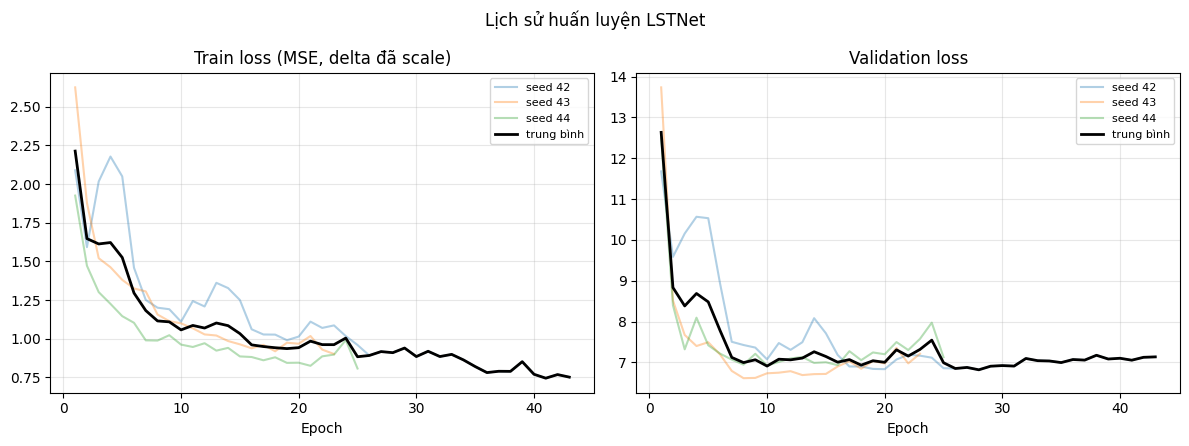

In [8]:
if PLOT.get("history", True):
    save_path = (
        None if init.save_plot is None else init.save_plot + "_history.png"
    )
    PlotHistory(list(histories.values()), seeds=list(histories.keys()),
                save_path=save_path)


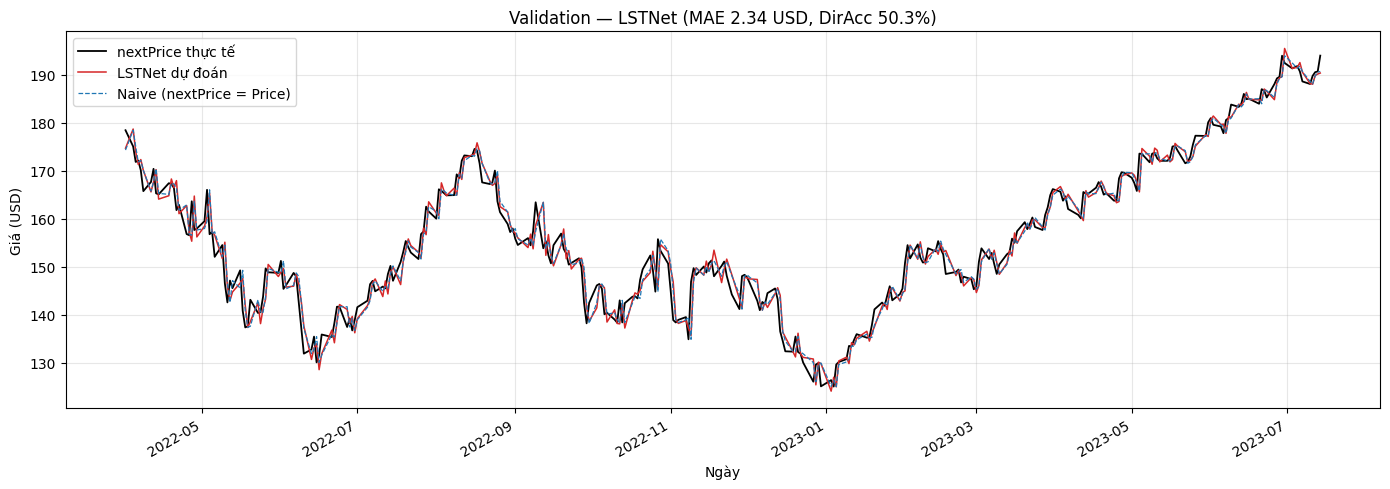

In [9]:
if PLOT.get("prediction", True):
    save_path = (
        None if init.save_plot is None else init.save_plot + "_val.png"
    )
    PlotPrediction(
        pd.to_datetime(Data.val.dates),
        Data.val.next_price,
        val_pred_mean,
        y_naive=Data.val.price_today,
        title=("Validation — LSTNet (MAE %.2f USD, DirAcc %.1f%%)"
               % (val_metrics_avg["MAE"], val_metrics_avg["DirAcc"])),
        save_path=save_path,
    )


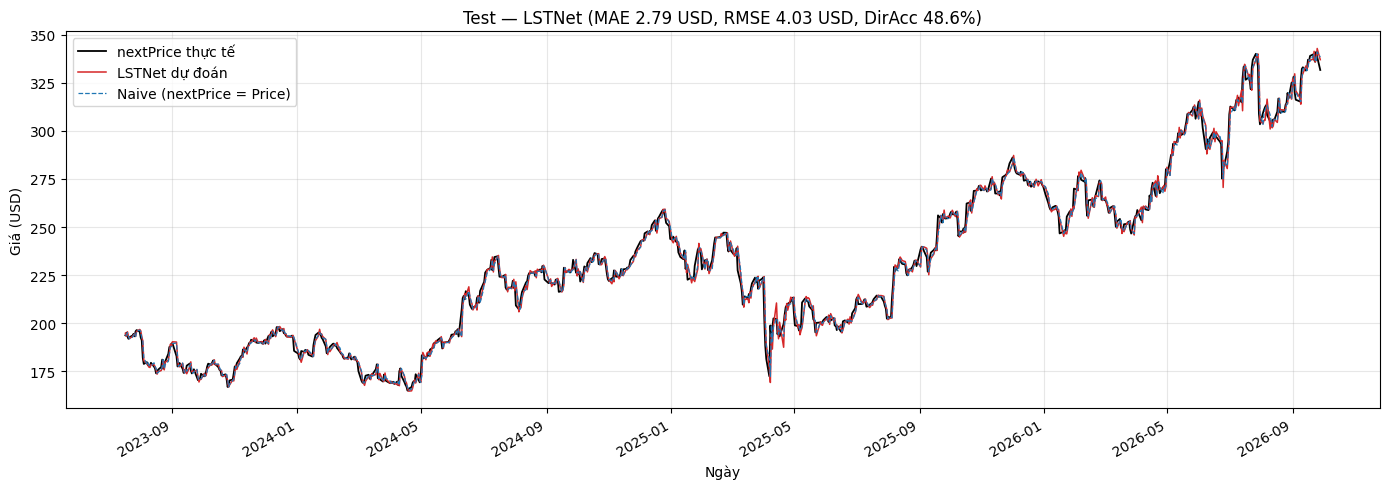

In [10]:
if PLOT.get("prediction", True):
    save_path = (
        None if init.save_plot is None else init.save_plot + "_test.png"
    )
    PlotPrediction(
        pd.to_datetime(Data.test.dates),
        Data.test.next_price,
        test_pred_mean,
        y_naive=Data.test.price_today,
        title=("Test — LSTNet (MAE %.2f USD, RMSE %.2f USD, DirAcc %.1f%%)"
               % (test_metrics_avg["MAE"], test_metrics_avg["RMSE"],
                  test_metrics_avg["DirAcc"])),
        save_path=save_path,
    )


## Ghi chú nhanh

- **Train lại từ đầu:** Restart Kernel → chạy lại từ cell 1.
- **Đổi số seed / epoch:** sửa `CONFIG.update(...)` ở cell 1.
- **Không muốn hiển thị biểu đồ:** đặt `PLOT["history"] = False` và/hoặc
  `PLOT["prediction"] = False`.
- **Lưu ý:** `train_val` và `test` dùng đuôi của tập trước để tạo cửa sổ,
  nên dự đoán phủ đủ mọi ngày trong tập (không mất mẫu đầu).
- Tài liệu đầy đủ về quy ước và kiến trúc: `README.ipynb`.


## 7. Xuất Kết quả Dự báo vào thư mục `model_predict`

- Dự báo biến động giá trên toàn bộ tập dữ liệu (4.020 dòng) bằng mô hình **LSTNet (3-Seed Ensemble)**.
- Khôi phục giá dự báo `price_pred` = $\text{Price}_t + \Delta_{\text{pred}}$.
- Lưu **duy nhất 1 file CSV** vào thư mục `model_predict`:
  - `model_predict/pred_LSTNet.csv` (gồm 2 cột `Date` và `price_pred`, độ dài bằng toàn bộ dataset 4.020 dòng).


In [11]:
# Xác định đường dẫn thư mục model_predict
predict_dir = None
for cand in ["model_predict", os.path.join("..", "model_predict"), os.path.join("..", "..", "model_predict")]:
    if os.path.exists(cand):
        predict_dir = cand
        break
if predict_dir is None:
    predict_dir = os.path.join("..", "..", "model_predict") if os.path.exists(os.path.join("..", "..")) else "model_predict"
os.makedirs(predict_dir, exist_ok=True)

# 1. Chuẩn bị đầu vào cho toàn bộ dataset (4.020 dòng) qua 3-Seed Ensemble
# X_all có shape (4020, 8), pad 29 dòng (window - 1) ở đầu bằng mode="edge"
padded_X = np.pad(Data.X_all, ((init.window - 1, 0), (0, 0)), mode="edge")
X_full = np.array([padded_X[i : i + init.window] for i in range(len(Data.df))], dtype=np.float32)

# AR (delta history): pad 7 giá trị (highway) ở đầu bằng mode="edge"
if init.highway > 0:
    padded_delta = np.pad(Data.delta_all, (init.highway, 0), mode="edge")
    AR_full = np.array([
        padded_delta[i : i + init.highway].reshape(-1, 1)
        for i in range(len(Data.df))
    ], dtype=np.float32)
else:
    AR_full = np.zeros((len(Data.df), 0, 1), dtype=np.float32)

# 2. Dự báo delta trên toàn bộ dataset bằng cả 3 seed đã huấn luyện
all_pred_deltas = []
for seed in init.seeds:
    m = models[seed]
    delta_scaled_all = m.predict([X_full, AR_full], verbose=0).ravel()
    delta_usd_all = Data.inverse_delta(delta_scaled_all)
    all_pred_deltas.append(delta_usd_all)

# Trung bình qua 3 seed (Ensemble)
ens_delta_all = np.mean(all_pred_deltas, axis=0)

# Khôi phục giá dự báo trên toàn bộ dataset: price_pred = Price_t + delta_pred
price_pred_all = Data.price_all + ens_delta_all

# Tạo DataFrame kết quả dự báo trên toàn bộ dataset (4.020 dòng)
date_series = Data.df[Data.date_col]
pred_full_df = pd.DataFrame({
    "Date": date_series.dt.strftime("%Y-%m-%d") if hasattr(date_series.iloc[0], "strftime") else date_series.astype(str).values,
    "price_pred": np.round(price_pred_all, 4)
})

# Xuất duy nhất 1 file CSV vào thư mục model_predict
output_csv_path = os.path.join(predict_dir, "pred_LSTNet.csv")
pred_full_df.to_csv(output_csv_path, index=False)

# Kiểm định tính toàn vẹn của file CSV đã xuất
assert len(pred_full_df) == 4020, f"Expected 4020 rows, got {len(pred_full_df)}"
assert pred_full_df.isna().sum().sum() == 0, "Found NaN in pred_LSTNet.csv!"

print(f"✓ Đã lưu thành công 1 file duy nhất vào: {output_csv_path}")
print(f"  - Số dòng: {len(pred_full_df)} (khớp toàn bộ dataset {len(Data.df)} dòng)")
print(f"  - Các cột: {list(pred_full_df.columns)}")
print(f"\nXem trước dữ liệu dự báo:")
print(pred_full_df.head(3).to_string(index=False))
print("...")
print(pred_full_df.tail(2).to_string(index=False))


✓ Đã lưu thành công 1 file duy nhất vào: ..\..\model_predict\pred_LSTNet.csv
  - Số dòng: 4020 (khớp toàn bộ dataset 4020 dòng)
  - Các cột: ['Date', 'price_pred']

Xem trước dữ liệu dự báo:
      Date  price_pred
2010-10-04     10.4273
2010-10-05     10.5099
2010-10-06     10.5325
...
      Date  price_pred
2026-09-25    342.8486
2026-09-28    337.0183
